# Model Explainability & Feature Importance

## 1 Model Explainability

### 1.1 Introduction

#### What is a Model in Liner Regression?

$$
\large
\hat{y}\;=\;w_1\,x_1\;+\;w_2\,x_2\;+\;\ldots\;+\;w_n\,x_n\;+\;w_0
$$

- A model in Liner Regression is a **Linear Equation** that has learned some coefficients.
- Model's coefficients are also called as model weights or simply weights represented using $w$ vector.
- When the relationship between $X$ and $y$ is linear, a Linear equation is chosen.
- When the relationship between $X$ and $y$ is non linear, a Polynomial equation is chosen.
- A model can be line, plane, $n$d Hyperplane depending on the size of feature vector $x$.

#### Model Explainability in Liner Regression

- Using Model coefficients to measure the impact of independent variables in predicting a dependent variable.
- Identifying important independent variables (features) that have higher impact in predicting dependent variable.
- The biggest advantage of Linear Regression is Model Explainability.

#### How to interpret weights?

If the linear relation between dependent variable $y$ and independent variables: $\{x_1,\,x_2,\,\ldots,\,x_n\}$ is:

$$
\large
\hat{y}\;=\;w_1\,x_1\;+\;-w_2\,x_2\;+\;\ldots\;+\;w_n\,x_n\;+\;w_0
$$

Then weights can be interpreted as:

- If $x_1$ **increases by one unit** then $y$ **increases** by $w_1$ units, assuming all other independent variables are constant.
- If $x_2$ **increases by one unit** then $y$ **decreases** by $w_2$ units, assuming all other independent variables are constant.

#### Correlation

Sign tells the direction of correlation:

- +ve sign indicates positive correlation i.e., $y$ increases as $x$ increases.
- -ve sign indicates negative correlation i.e., $y$ decreases as $x$ increases.

#### Model Explainability Example

##### Linear Equation Model

Given a Linear equation for predicting the resale price - $\hat{y}$ - of a car, say in dollars, as:

$$
\large
\hat{y}\;=\;-100\,\text{age}\;+\;10\,\text{millage}\;+\;\ldots\;+\;-25\,\text{odometer}\;+\;w_0
$$

##### Interpretation

- As _age_ of the car **increases by 1 year**, resale price of the car **reduces by \$100**.
- As _odometer_ reading **increases by 1 kilometer**, resale price of the car **reduces by \$25**.
- As _millage_ of the car **increases by 1 kilometer**, resale price of the car **increases by \$10**.
- It is **incorrect** to conclude _age_ is more important than _odometer_ is more important than _millage_ in deciding resale price.

### 1.2 Feature Importance

#### Feature Importance vs Coefficients

- Model coefficients can be used to determine feature importance.
- Coefficients without feature scaling cannot be used for interpreting feature importance.

#### Impact of Feature Scaling

- Feature scaling is done to give **equal importance to all features** in different scales.
- Scaling does not change the underlying predictive relationship represented by the model.
- When features have different units or scales, raw coefficients cannot be compared directly with one another to determine feature importance.
- Feature scaling can help **compare the magnitudes of different coefficients** by bringing them all to same scale.
- After scaling, higher the magnitude of coefficients (ignoring the sign), higher will be the importance of their corresponding feature in determining the target value.
- Feature scaling smoothens the Gradient Descent and is not over influenced by a feature in larger scale.

## 2 Model Explainability Experiment

### 2.1 Setup

In [1]:
import warnings

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.linear_model import LinearRegression

In [2]:
RANDOM_STATE = 42

# Configure NumPy.
rng = np.random.default_rng(seed=RANDOM_STATE)
np.set_printoptions(linewidth=100)

# Configure Seaborn.
sns.set_style("whitegrid")
sns.set_palette("deep")

warnings.filterwarnings("ignore")

#### Dataset

In [3]:
data = [
    [10, 15, 900, 3_650],  # 10 years old car, 15 km millage, 900 km odometer reading costs: $3,650
    [5, 10, 400, 16_600],  # 5 years old car, 10 km millage, 400 km odometer reading costs: $16,600
    [1, 10, 200, 22_000],  # 1 year old car, 10 km millage, 200 km odometer reading costs: $22,000
    [8, 13, 600, 11_330],  # 8 years old car, 13 km millage, 600 km odometer reading costs: $11,330
    [5, 15, 400, 16_650],  # 5 years old car, 15 km millage, 400 km odometer reading costs: $16,650
]
col_names = ["Age", "Millage", "Odometer", "ResalePrice"]

df = pd.DataFrame(data=data, columns=col_names)
df

,Age,Millage,Odometer,ResalePrice
0,10,15,900,3650
1,5,10,400,16600
2,1,10,200,22000
3,8,13,600,11330
4,5,15,400,16650


#### Linear relation b/w Features & Target

In [4]:
X = df.drop(columns="ResalePrice")  # Features
y = df["ResalePrice"]  # Target

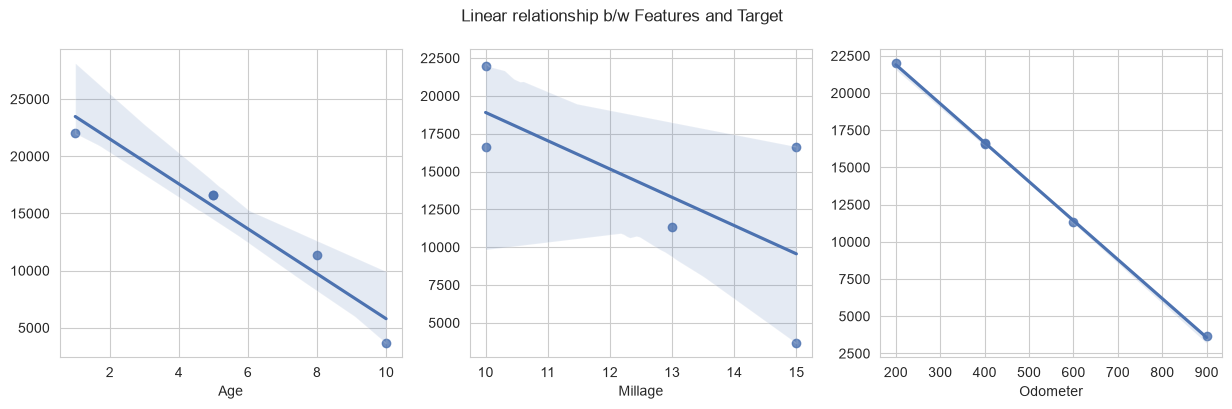

In [5]:
plt.figure(figsize=(15, 4))
plt.suptitle("Linear relationship b/w Features and Target")

for idx, col_name in enumerate(X.columns, start=1):
    plt.subplot(1, 3, idx)
    sns.regplot(x=df[col_name].values, y=df["ResalePrice"].values)
    plt.xlabel(col_name)

plt.show()

### 2.2 Training Without Scaling

#### Linear Regression Model

In [6]:
model1 = LinearRegression()
model1.fit(X, y)

print("Model coefficients without scaling:", model1.coef_.round(6).tolist())

Model coefficients without scaling: [-100.0, 10.0, -25.0]


##### Model Coefficients

In [7]:
fc1_df = (
    pd.DataFrame(
        data={
            "Feature": model1.feature_names_in_,
            "Coefficient": model1.coef_,
        }
    )
    .sort_values(by="Coefficient", ascending=False)
    .reset_index(drop=True)
)
fc1_df

,Feature,Coefficient
0,Millage,10.0
1,Odometer,-25.0
2,Age,-100.0


#### Properties

Properties of Coefficients without scaling:

- It is **incorrect** to conclude _Age_ is more important than _Odometer_ is more important than _Millage_ in deciding resale price.
- Coefficients are attached to features measured in completely different units or scales.
- Coefficients without feature scaling cannot be used for interpreting feature importance.

#### Example #1

##### Model Explainability

- Training dataset shows a 10 years old car with 15 km millage and 900 km odometer reading costs: \$3,650.
- _Age_ has a negative coefficient value of $-100$ indicating as _Age_ increases _ResalePrice_ reduces.
- **One year increase in age** of car keeping all other features as constant should **reduce the resale price** by \$100 (age coefficient).
- Expected resale price to be predicted by a Linear Regression model is 3,650 - 100 = \$3,550.

In [8]:
y1_pred = model1.predict([[11, 15, 900]]).item()
print(
    f"Predicted resale price of 11 years old car with"
    f" 15 km millage and 900 km odometer reading is: ${y1_pred:,.0f}"
)

Predicted resale price of 11 years old car with 15 km millage and 900 km odometer reading is: $3,550


#### Example #2

##### Model Explainability

- Training dataset shows a 10 years old car with 15 km millage and 900 km odometer reading costs: \$3,650.
- _Age_ has a negative coefficient value of $-100$ indicating as _Age_ decreases _ResalePrice_ increases.
- **One year decrease in age** of car keeping all other features as constant should **increase the resale price** by \$100 (age coefficient).
- Expected resale price to be predicted by a Linear Regression model is 3,650 + 100 = \$3,750.

In [9]:
y2_pred = model1.predict([[9, 15, 900]]).item()

print(
    f"Predicted resale price of 9 years old car with"
    f" 15 km millage and 900 km odometer reading is: ${y2_pred:,.0f}"
)

Predicted resale price of 9 years old car with 15 km millage and 900 km odometer reading is: $3,750


### 2.3 Training With Standardization

#### Feature Scaling

In [10]:
std_sclr = StandardScaler().set_output(transform="pandas")
X_std_scld = std_sclr.fit_transform(X)

##### Scaling parameters

In [11]:
std_df = pd.DataFrame(
    data={
        "Feature": std_sclr.get_feature_names_out(),
        "mean": std_sclr.mean_,
        "std": std_sclr.scale_,
    }
)
std_df

,Feature,mean,std
0,Age,5.8,3.059412
1,Millage,12.6,2.244994
2,Odometer,500.0,236.643191


#### Linear Regression Model

In [12]:
model2 = LinearRegression()
model2.fit(X_std_scld, y)

print("Model coefficients after scaling:", model2.coef_.round(6).tolist())

Model coefficients after scaling: [-305.941171, 22.449944, -5916.079783]


##### Model Coefficients

In [13]:
fc2_df = (
    pd.DataFrame(
        data={
            "Feature": model2.feature_names_in_,
            "Coefficient": model2.coef_,
        }
    )
    .sort_values(by="Coefficient", ascending=False)
    .reset_index(drop=True)
)
fc2_df

,Feature,Coefficient
0,Millage,22.449944
1,Age,-305.941171
2,Odometer,-5916.079783


#### Properties

Properties of Coefficients after scaling:

- Model Explainability using coefficients is NOT lost after feature scaling.
- Feature scaling changes the numerical values of the coefficients.
- Scaling does not change the underlying predictive relationship represented by the model.

#### Example #3

In [14]:
age_std = std_df[std_df["Feature"] == "Age"]["std"].item()
age_cof_bfs = fc1_df[fc1_df["Feature"] == "Age"]["Coefficient"].item()
age_cof_afs = fc2_df[fc2_df["Feature"] == "Age"]["Coefficient"].item()

print(f"Standard deviation of Age feature: {age_std:.2f}")
print(f"Coefficient of Age feature (before scaling): {age_cof_bfs:.2f}")
print(f"Coefficient of Age feature (after scaling): {age_cof_afs:.2f}")

Standard deviation of Age feature: 3.06
Coefficient of Age feature (before scaling): -100.00
Coefficient of Age feature (after scaling): -305.94


##### Model Explainability

- Training dataset shows a 10 years old car with 15 km millage and 900 km odometer reading costs: \$3,650
- _Age_ has a negative coefficient value of $-305.94$ indicating as _Age_ increases _ResalePrice_ reduces.
- **One standard deviation increase in age** keeping all other features as constant should **decrease resale price** by \$305.94.
- Expected resale price to be predicted by a Linear Regression model is 3,650 - 305.94 = \$3,344.06

In [15]:
one_sd_age = 10 + (1 * age_std)
exp_price3 = 3_650 - np.abs(1 * age_cof_afs)

print(f"Expected resale price of {round(one_sd_age)} years old car is: ${exp_price3:,.0f}")

Expected resale price of 13 years old car is: $3,344


In [16]:
x3_scaled = std_sclr.transform([[one_sd_age, 15, 900]])
y3_pred = model2.predict(x3_scaled).item()

print(
    f"Predicted resale price of {round(one_sd_age)} years old car with"
    f" 15 km millage and 900 km odometer reading is: ${y3_pred:,.0f}"
)

Predicted resale price of 13 years old car with 15 km millage and 900 km odometer reading is: $3,344


#### Example #4

In [17]:
x4_scaled = std_sclr.transform([[11, 15, 900]])
y4_pred = model2.predict(x4_scaled).item()

print(
    f"Predicted resale price of 11 years old car with"
    f" 15 km millage and 900 km odometer reading is: ${y4_pred:,.0f}"
)

Predicted resale price of 11 years old car with 15 km millage and 900 km odometer reading is: $3,550


##### Observations

- Feature Scaling does not change the predictive outcome of a model.
- Predicted resale price of 11 year old car - \$3,500 - was same with and without feature scaling.

#### Example #5

##### Model Explainability

- Training dataset shows a 10 years old car with 15 km millage and 900 km odometer reading costs: \$3,650
- _Age_ has a negative coefficient value of $-305.94$ indicating as _Age_ decreases _ResalePrice_ increases.
- **Two standard deviation decrease in age** keeping all other features as constant should **increase resale price** by 2 X 305.94 = \$611.88.
- \$611.88 is approximately twice the coefficient of age feature.
- Expected resale price to be predicted by a Linear Regression model is 3,650 + 611.88 = \$4,261.88

In [18]:
two_sd_age = 10 - (2 * age_std)
exp_price5 = 3_650 + np.abs(2 * age_cof_afs)

print(f"Expected resale price of {round(two_sd_age)} years old car is: ${exp_price5:,.0f}")

Expected resale price of 4 years old car is: $4,262


In [19]:
x5_scaled = std_sclr.transform([[two_sd_age, 15, 900]])
y5_pred = model2.predict(x5_scaled).item()

print(
    f"Predicted resale price of {round(two_sd_age)} years old car with"
    f" 15 km millage and 900 km odometer reading is: ${y5_pred:,.0f}"
)

Predicted resale price of 4 years old car with 15 km millage and 900 km odometer reading is: $4,262


##### Observations

- Feature Scaling does not change the predictive outcome of a model.
- Predicted resale price of car - \$3,500 - was same with and without feature scaling.

#### Feature Importance

For coefficient-based feature importance, scaling can substantially improve interpretability:

- Without scaling, coefficients can be used to measure the linear relation between independent and dependent variable.
- Without scaling, coefficients cannot be compared with one another since they are attached to features measured in different units/scales.
- After scaling, coefficients become much more comparable without loosing Model Explainability.
- After scaling, coefficient's numerical magnitudes are unit-dependent.

In [20]:
fi1_df = (
    pd.DataFrame(
        data={
            "Feature": model2.feature_names_in_,
            "Importance": np.abs(model2.coef_),
        }
    )
    .sort_values(by="Importance", ascending=False)
    .reset_index(drop=True)
)
fi1_df

,Feature,Importance
0,Odometer,5916.079783
1,Age,305.941171
2,Millage,22.449944


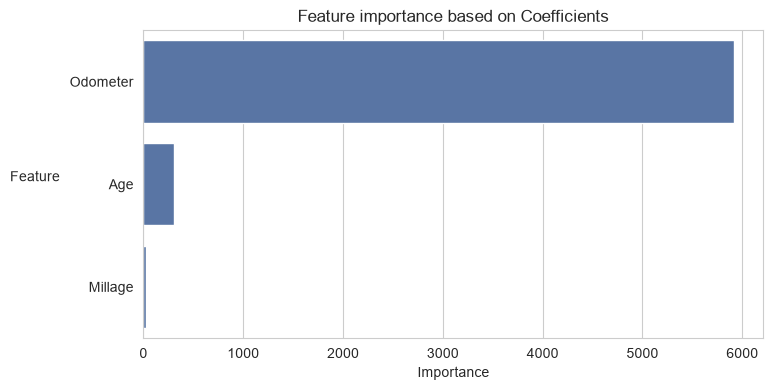

In [21]:
plt.figure(figsize=(8, 4))

sns.barplot(fi1_df, x="Importance", y="Feature")
plt.title("Feature importance based on Coefficients")
plt.ylabel("Feature", rotation=0, labelpad=25)

plt.show()

##### Observations

- Feature _Odometer_ has a larger standardized linear effect on target compared to _Age_ and  _Millage_.
- Feature _Odometer_ is more important than _Age_ is more important than _Millage_ in predicting resale price of the car

### 2.4 Training With Min-Max Scaler

#### Feature Scaling

In [22]:
mm_sclr = MinMaxScaler().set_output(transform="pandas")
X_mm_scld = mm_sclr.fit_transform(X)

#### Linear Regression Model

In [23]:
model3 = LinearRegression()
model3.fit(X_mm_scld, y)

print("Model coefficients after scaling:", model3.coef_.round(6).tolist())

Model coefficients after scaling: [-900.0, 50.0, -17500.0]


##### Model Coefficients

In [24]:
fc3_df = (
    pd.DataFrame(
        data={
            "Feature": model3.feature_names_in_,
            "Coefficient": model3.coef_,
        }
    )
    .sort_values(by="Coefficient", ascending=False)
    .reset_index(drop=True)
)
fc3_df

,Feature,Coefficient
0,Millage,50.0
1,Age,-900.0
2,Odometer,-17500.0


#### Feature Importance

In [25]:
fi3_df = (
    pd.DataFrame(
        data={
            "Feature": model3.feature_names_in_,
            "Importance": np.abs(model3.coef_),
        }
    )
    .sort_values(by="Importance", ascending=False)
    .reset_index(drop=True)
)
fi3_df

,Feature,Importance
0,Odometer,17500.0
1,Age,900.0
2,Millage,50.0


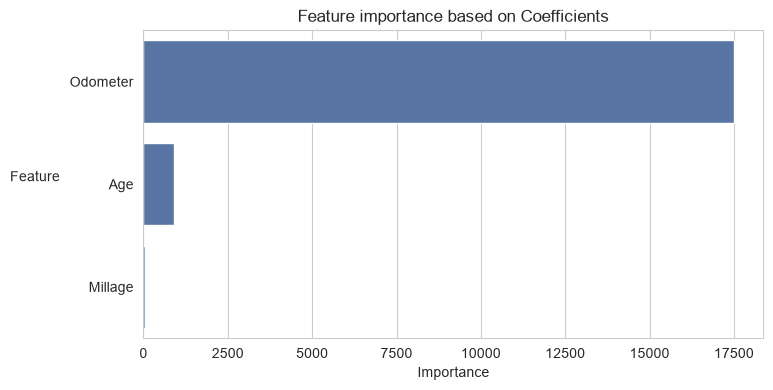

In [26]:
plt.figure(figsize=(8, 4))

sns.barplot(fi3_df, x="Importance", y="Feature")
plt.title("Feature importance based on Coefficients")
plt.ylabel("Feature", rotation=0, labelpad=25)

plt.show()